# Лабораторная работа №4 — задание 1

Проверяем условие теоремы 1.1:

$$
U(x^*, f)\cap V(x^*, X)=\varnothing
$$

в локальном минимуме на выпуклом множестве.

Для дифференцируемой функции используем:

$$
h\in U(x^*, f)\Leftarrow \nabla f(x^*)^T h<0.
$$

In [2]:
import numpy as np
import matplotlib.pyplot as plt

TOL = 1e-10

In [3]:
def is_descent_direction(grad_f, h, tol=TOL):
    """Проверяет grad f(x*)^T h < 0."""
    return np.dot(grad_f, h) < -tol


def feasible_box(x_star, h, lower, upper, tol=TOL):
    x_star, h = np.asarray(x_star), np.asarray(h)
    lower, upper = np.asarray(lower), np.asarray(upper)

    on_lower = np.isclose(x_star, lower, atol=tol, rtol=0)
    on_upper = np.isclose(x_star, upper, atol=tol, rtol=0)

    violation = (on_lower & (h < -tol)) | (on_upper & (h > tol))
    return not np.any(violation)


def feasible_ball(x_star, h, center, radius, tol=TOL):
    """Точное малое движение внутри шара."""
    r = np.asarray(x_star) - np.asarray(center)

    distance_squared = np.dot(r, r)

    if distance_squared > radius**2 + tol:
        return False

    if distance_squared < radius**2 - tol:
        return True

    if np.linalg.norm(h) <= tol:
        return True

    return np.dot(r, h) < -tol


def feasible_orthant(x_star, h, tol=TOL):
    x_star, h = np.asarray(x_star), np.asarray(h)
    on_boundary = np.isclose(x_star, 0, atol=tol, rtol=0)
    return np.all(h[on_boundary] >= -tol)


def feasible_halfspace(x_star, h, normal, bound, tol=TOL):
    x_star, h, normal = map(np.asarray, (x_star, h, normal))
    value = np.dot(normal, x_star)
    on_boundary = np.isclose(value, bound, atol=tol, rtol=0)

    if value > bound and not on_boundary:
        return False
    if value < bound and not on_boundary:
        return True

    return np.dot(normal, h) <= tol


def feasible_descent(grad_f, x_star, h, checker, tol=TOL):
    return is_descent_direction(grad_f, h, tol) and checker(x_star, h, tol=tol)

## Проверка на параллелепипеде

$$
f(x)=(x_1-1)^2+(x_2-1)^2,\qquad
X=[0,2]^2.
$$

Точка минимума:

$$
x^*=(1,1),\qquad \nabla f(x^*)=0.
$$

Случайно генерируем 200 направлений для каждой точки сетки. Вычисления по направлениям выполняются векторно.

Направлений в точке x*=[1. 1.]: 0


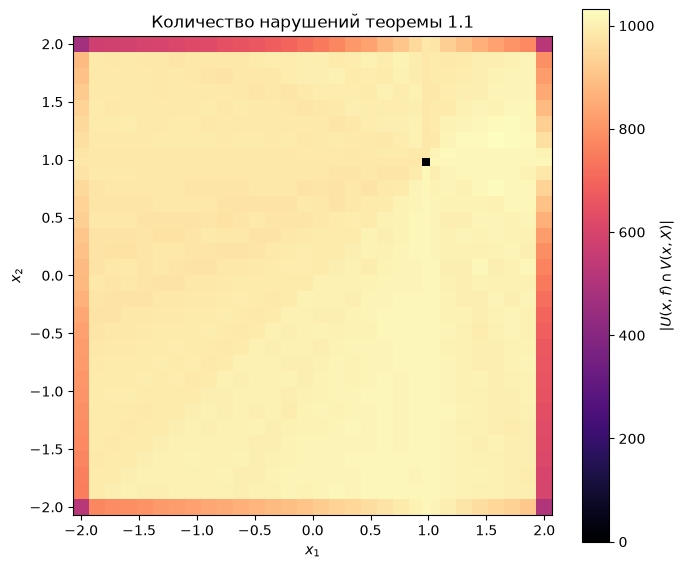

In [24]:
LOWER, UPPER = -2.0, 2.0
GRID_SIZE = 30
N_DIRECTIONS = 2000
SEED = 42
TOL = 1e-10
X_STAR = np.array([1.0, 1.0])

base_grid = np.linspace(LOWER, UPPER, GRID_SIZE)
grid = np.unique(np.concatenate((base_grid, X_STAR)))
X1, X2 = np.meshgrid(grid, grid, indexing="xy")
points = np.column_stack((X1.ravel(), X2.ravel()))  # (P, 2)

rng = np.random.default_rng(SEED)
dirs = rng.normal(size=(N_DIRECTIONS, 2))
dirs /= np.linalg.norm(dirs, axis=1, keepdims=True)  # (J, 2)

grads = 2.0 * (points - X_STAR)  # (P, 2)

# 1) направления убывания: grads @ h < 0
descent = grads @ dirs.T < -TOL  # (P, J)

# 2) возможные направления
on_lower = np.isclose(points, LOWER, atol=TOL)  # (P, 2)
on_upper = np.isclose(points, UPPER, atol=TOL)  # (P, 2)

violates = (
    (on_lower[:, None, :] & (dirs[None, :, :] < -TOL))
    | (on_upper[:, None, :] & (dirs[None, :, :] > TOL))
).any(axis=2)  # (P, J)

counts = (descent & ~violates).sum(axis=1).reshape(X1.shape)

idx = np.argmin(np.linalg.norm(points - X_STAR, axis=1))
print(f"Направлений в точке x*={X_STAR}: {counts.ravel()[idx]}")

# График
fig, ax = plt.subplots(figsize=(7, 6))
mesh = ax.pcolormesh(X1, X2, counts, shading="auto", cmap="magma")
ax.set(
    xlabel="$x_1$",
    ylabel="$x_2$",
    title="Количество нарушений теоремы 1.1",
    aspect="equal",
)
fig.colorbar(mesh, ax=ax, label=r"$|U(x,f)\cap V(x,X)|$")
plt.tight_layout()
plt.show()

В точке $x^*=(1,1)$ градиент равен нулю, поэтому направлений строгого убывания нет. В остальных точках пересечение $U(x,f)\cap V(x,X)$ может быть непустым.

## Двумерный пример с полупространством

$$
f(x)=x_1^2+x_2^2,\qquad
X=\{x:x_1+x_2\ge 1\}.
$$

Проекция начала координат на границу даёт минимум:

$$
x^*=\left(\frac12,\frac12\right).
$$

Для демонстрации нарушения необходимого условия возьмём точку
$$
x_{\mathrm{bad}}=(1,0).
$$
Она допустима, но не является минимумом.

В точке $x_{\mathrm{bad}}=(1,0)$:

$$
\nabla f(x_{\mathrm{bad}})=(2,0).
$$

Например, $h=(-1,2)$ удовлетворяет:

$$
\nabla f(x_{\mathrm{bad}})^T h=-2<0,
\qquad
h_1+h_2=1>0.
$$

Следовательно,

$$
h\in U(x_{\mathrm{bad}},f)\cap V(x_{\mathrm{bad}},X),
$$

поэтому $x_{\mathrm{bad}}$ не является локальным минимумом.

f(x*) = 0.5
Размер конуса V(x*, X): 180 направлений
Направлений убывания в конусе (нарушений): 0
Нарушений в x_bad: 45


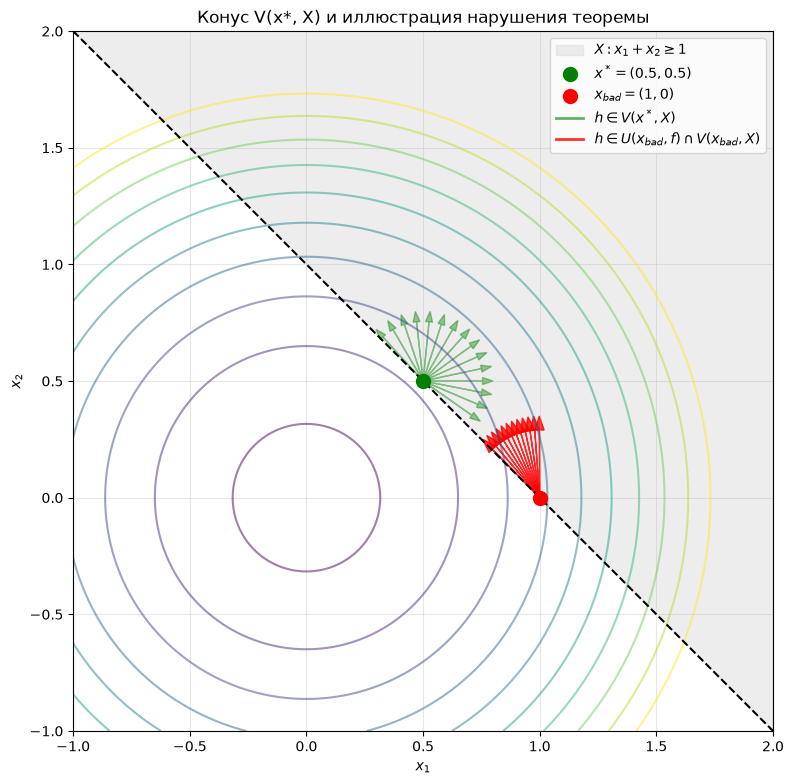

In [29]:
import numpy as np
import matplotlib.pyplot as plt

def f_circle(x):
    return np.sum(x**2, axis=-1)

x_star = np.array([0.5, 0.5])
x_bad = np.array([1.0, 0.0])

normal = np.array([1.0, 1.0]) # Внутренняя нормаль к границе

angles = np.linspace(0, 2 * np.pi, 360)
directions = np.column_stack((np.cos(angles), np.sin(angles)))

# --- 1. Конус V(x*, X) ---
# В точке x* допустимы направления, не выводящие из X: normal^T h >= 0
feasible_star = directions @ normal >= 0
V_star = directions[feasible_star]

# Проверяем убывание в x*: grad_star^T h < 0
grad_star = 2 * x_star # = [1, 1]
descent_star = V_star @ grad_star < 0
bad_in_star = V_star[descent_star]

print(f"f(x*) = {f_circle(x_star)}")
print(f"Размер конуса V(x*, X): {len(V_star)} направлений")
print(f"Направлений убывания в конусе (нарушений): {len(bad_in_star)}")

# --- 2. Конус нарушения в x_bad ---
feasible_bad = directions @ normal >= 0
V_bad = directions[feasible_bad]
grad_bad = 2 * x_bad # = [2, 0]
descent_bad = V_bad @ grad_bad < 0
good_bad = V_bad[descent_bad] # Это направления, где теорема нарушается

print(f"Нарушений в x_bad: {len(good_bad)}")

# --- 3. График ---
fig, ax = plt.subplots(figsize=(8, 8))

# Кривые уровня f
x = np.linspace(-1.0, 2.0, 400)
y = np.linspace(-1.0, 2.0, 400)
XX, YY = np.meshgrid(x, y)
ax.contour(XX, YY, XX**2 + YY**2, levels=np.linspace(0.1, 3, 10), cmap="viridis", alpha=0.5)

# Область X
ax.fill_between(x, 1 - x, 2.5, color="lightgray", alpha=0.4, label=r"$X: x_1+x_2\geq 1$")
ax.plot(x, 1 - x, "k--", linewidth=1.5)

# Точки
ax.scatter(*x_star, color="green", s=100, zorder=5, label=r"$x^*=(0.5, 0.5)$")
ax.scatter(*x_bad, color="red", s=100, zorder=5, label=r"$x_{bad}=(1, 0)$")

# Рисуем векторы h из конуса V(x*, X) из точки x* (зеленые)
for h in V_star[::max(1, len(V_star)//15)]:
    ax.arrow(x_star[0], x_star[1], 0.3*h[0], 0.3*h[1],
             color="green", alpha=0.4, head_width=0.03, length_includes_head=True)

# Рисуем векторы нарушения из x_bad (красные)
for h in good_bad[::max(1, len(good_bad)//10)]:
    ax.arrow(x_bad[0], x_bad[1], 0.35*h[0], 0.35*h[1],
             color="red", alpha=0.8, head_width=0.04, length_includes_head=True)

# Оформление
ax.set_aspect("equal")
ax.set_xlim(-1.0, 2.0)
ax.set_ylim(-1.0, 2.0)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Конус V(x*, X) и иллюстрация нарушения теоремы")
ax.grid(alpha=0.3)

# Легенда
from matplotlib.lines import Line2D
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color="green", alpha=0.6, lw=2, label=r"$h \in V(x^*, X)$"))
handles.append(Line2D([0], [0], color="red", alpha=0.8, lw=2, label=r"$h \in U(x_{bad}, f) \cap V(x_{bad}, X)$"))
ax.legend(handles=handles, loc="upper right")

plt.tight_layout()
plt.show()